##### Copyright 2026 The Contributors

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
See the LICENSE file in the repository root.


# 03 — Dataset preparation

Temporal train/test split, a hard leakage assertion, and feature-column
selection. Also inspects per-feature correlation with the target so you can
catch accidental leakage (a feature that's suspiciously *too* predictive
usually means it secretly encodes the future).

## Prerequisites
- `artifacts/labeled.csv` from notebook `02`


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
print("ROOT =", ROOT)


ROOT = /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks


In [2]:
from utils import ARTIFACTS_DIR, load_data, save_data
from pipeline.dataset import prepare_train_test, get_feature_columns, validate_no_future_leakage

labeled = load_data(ARTIFACTS_DIR / "labeled.csv")
labeled["month"] = pd.to_datetime(labeled["month"])
labeled["target_month"] = pd.to_datetime(labeled["target_month"])
print(f"{len(labeled)} rows, months {labeled['month'].min().date()} -> {labeled['month'].max().date()}")


5700 rows, months 2024-01-01 -> 2025-07-01


## Leakage check

This assertion is not optional -- run it every time you touch the feature or
target code. It only checks the timing invariant (`month < target_month`);
it cannot catch every possible leakage, so treat "no features with >0.95
correlation" warnings from `validate_no_future_leakage` as a prompt to
manually review that feature, not as proof of safety.


In [3]:
validate_no_future_leakage(labeled)


INFO | Leakage check passed (month < target_month for all rows)


## Temporal train/test split

We split by **calendar month**, not by random row sampling. A random split
would let the model "peek" at other hexagons in the same month it's being
tested on -- unrealistic, since in production you only ever have the past.


INFO | Split: train 2024-01-01→2025-05-01 (5100) | test 2025-06-01→2025-07-01 (600)


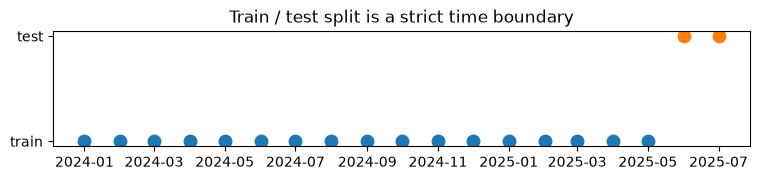

In [4]:
train_df, test_df = prepare_train_test(labeled, test_months=2)

fig, ax = plt.subplots(figsize=(9, 1.5))
for label, df, color in [("train", train_df, "tab:blue"), ("test", test_df, "tab:orange")]:
    months = sorted(df["month"].unique())
    ax.scatter(months, [label] * len(months), color=color, s=80)
ax.set_title("Train / test split is a strict time boundary")
plt.show()


## Feature selection

Only numeric, non-label, non-identifier columns are used as model inputs.
`get_feature_columns` excludes ids/dates/labels automatically -- print the
result so you know exactly what the model can and cannot see.


In [5]:
feature_cols = get_feature_columns(train_df)
save_data(train_df, ARTIFACTS_DIR / "train.csv")
save_data(test_df, ARTIFACTS_DIR / "test.csv")
pd.Series(feature_cols).to_csv(ARTIFACTS_DIR / "feature_cols.csv", index=False, header=["feature"])

print(f"{len(feature_cols)} feature columns:")
for c in feature_cols:
    print(" -", c)


INFO | Saved 5100 rows -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/artifacts/train.csv


INFO | Saved 600 rows -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/artifacts/test.csv


25 feature columns:
 - total_cases
 - avg_age
 - pulmonary_cases
 - relapse_rate
 - hiv_positive_count
 - diabetes_count
 - weighted_infectivity_load
 - pulmonary_percentage
 - cases_t_minus_1
 - cases_t_minus_2
 - cases_t_minus_3
 - cases_sum_3mo
 - cases_3month_rolling_avg
 - cases_sum_6mo
 - mom_trend
 - persistence_score
 - days_since_last_case
 - n_contacts
 - slum_density
 - neighbor_risk_ring1
 - hotspot_encirclement
 - cases_x_slum
 - neighbor_x_slum
 - lag1_x_persistence
 - transmission_vulnerability_score


## Correlation-with-target sanity check

Anything above ~0.9 correlation with `target_cases` deserves a second look --
it might be legitimate (e.g. `cases_t_minus_1` naturally correlates with
next month if TB persists spatially) or it might be a leak. Judge case by
case; don't blindly drop high-correlation features.


In [6]:
corr = train_df[feature_cols + ["target_cases"]].corr()["target_cases"].drop("target_cases").sort_values(ascending=False)
print(corr.head(10))
suspicious = corr[corr.abs() > 0.9]
if len(suspicious):
    print("\n⚠️  Review these before trusting the model:")
    print(suspicious)
else:
    print("\nNo single feature has >0.9 correlation with the target -- no obvious leak.")


slum_density                        0.427347
transmission_vulnerability_score    0.366871
neighbor_x_slum                     0.318635
cases_x_slum                        0.276077
cases_3month_rolling_avg            0.274080
cases_sum_3mo                       0.259635
cases_sum_6mo                       0.226356
total_cases                         0.209327
weighted_infectivity_load           0.192014
pulmonary_cases                     0.180148
Name: target_cases, dtype: float64

No single feature has >0.9 correlation with the target -- no obvious leak.
